<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/BoxBehnken.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Box-Behnken design for pectin extraction and its Fisher information (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $X_1,X_2,X_3\in\{-1,0,1\}$ | `x1`, `x2`, `x3` | scaled temperature, time, acid concentration |
| $\mathbf{y}$ | `y` | measured yields [%] |
| $\mathbf{X}$ | `X` | design matrix ($S\times 10$) |
| $\mathcal{I}=\mathbf{X}^T\mathbf{X}$ | `FI` | Fisher information (scaled by the noise variance) |
| $\hat{\theta}$ | `theta_hat` | parameter estimates |
| $\hat{\sigma}$ | `sigma_hat` | estimated noise SD |
| $\mathrm{Cov}[\hat{\theta}]$ | `Cov_theta` | parameter covariance |

**Note:** This notebook reproduces the response-surface example of the slides: a Box-Behnken design of 17 experiments, the quadratic model it supports, and the information it contains.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

D = np.loadtxt(path + "Data/box_behnken.dat")
x1, x2, x3 = D[:, 0], D[:, 1], D[:, 2]   # scaled temperature, time, acid concentration
y = D[:, 3]                              # pectin yield [%]
S = len(y)                               # number of experiments
print(pd.DataFrame(D, columns=["X1", "X2", "X3", "yield [%]"]).to_string())

     X1   X2   X3  yield [%]
0   0.0 -1.0  1.0      14.23
1   1.0  0.0 -1.0      17.28
2  -1.0  0.0  1.0      10.74
3  -1.0  0.0 -1.0      10.31
4   0.0  0.0  0.0      16.46
5  -1.0 -1.0  0.0       9.42
6   0.0  0.0  0.0      16.82
7   0.0  0.0  0.0      16.65
8  -1.0  1.0  0.0      11.39
9   0.0 -1.0 -1.0      13.02
10  0.0  1.0 -1.0      15.37
11  1.0  0.0  1.0      18.47
12  1.0  1.0  0.0      19.18
13  0.0  0.0  0.0      16.42
14  1.0 -1.0  0.0      17.78
15  0.0  1.0  1.0      15.91
16  0.0  0.0  0.0      16.54


The design covers the midpoints of the edges of the cube, plus five replicates of the center.

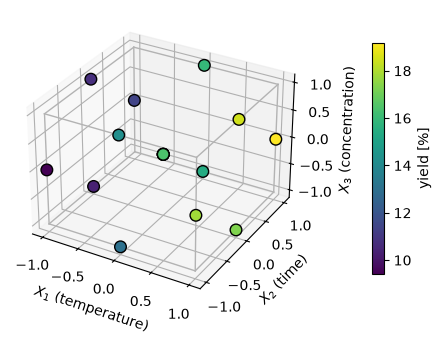

In [3]:
fig = plt.figure(figsize=(5.5, 5))
ax = fig.add_subplot(projection="3d")
p = ax.scatter(x1, x2, x3, c=y, cmap="viridis", s=70, edgecolors="k", depthshade=False)
for a in (-1, 1):
    for c in (-1, 1):
        ax.plot([-1, 1], [a, a], [c, c], color="0.7", lw=1)
        ax.plot([a, a], [-1, 1], [c, c], color="0.7", lw=1)
        ax.plot([a, a], [c, c], [-1, 1], color="0.7", lw=1)
ax.set_xlabel("$X_1$ (temperature)"); ax.set_ylabel("$X_2$ (time)"); ax.set_zlabel("$X_3$ (concentration)")
fig.colorbar(p, label="yield [%]", shrink=0.6, pad=0.15)
plt.show()

Design matrix for the model $Y=\theta_0+\theta_1X_1+\theta_2X_2+\theta_3X_3+\theta_4X_1^2+\theta_5X_2^2+\theta_6X_3^2+\theta_7X_1X_2+\theta_8X_1X_3+\theta_9X_2X_3$, and its Fisher information $\mathcal{I}=\mathbf{X}^T\mathbf{X}$.

eigenvalues of I: [ 2.635  4.     4.     4.     4.     4.     8.     8.     8.    30.365]


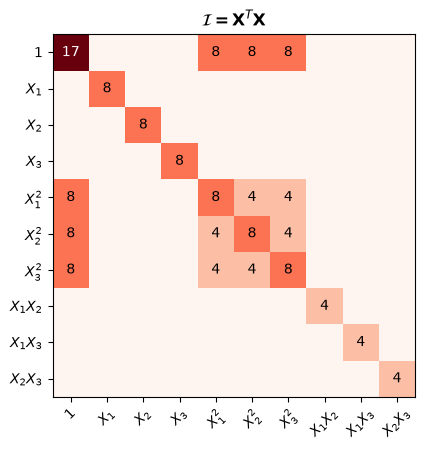

In [4]:
X = np.column_stack([np.ones(S), x1, x2, x3, x1**2, x2**2, x3**2, x1*x2, x1*x3, x2*x3])
FI = X.T @ X
names = [r"$1$", r"$X_1$", r"$X_2$", r"$X_3$", r"$X_1^2$", r"$X_2^2$", r"$X_3^2$", r"$X_1X_2$", r"$X_1X_3$", r"$X_2X_3$"]

print("eigenvalues of I:", np.round(np.linalg.eigvalsh(FI), 3))
plt.figure(figsize=(5.5, 4.6))
plt.imshow(FI, cmap="Reds")
for i in range(10):
    for j in range(10):
        if FI[i, j] != 0:
            plt.text(j, i, f"{FI[i, j]:.0f}", ha="center", va="center", color="white" if FI[i, j] > 9 else "black")
plt.xticks(range(10), names, rotation=45); plt.yticks(range(10), names)
plt.title(r"$\mathcal{I}=\mathbf{X}^T\mathbf{X}$")
plt.tight_layout(); plt.show()

Estimates $\hat{\theta}=(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$, noise variance
$\hat{\sigma}^2=SSE/(S-10)$ and covariance $\mathrm{Cov}[\hat{\theta}]=\hat{\sigma}^2(\mathbf{X}^T\mathbf{X})^{-1}$.

In [5]:
theta_hat = np.linalg.solve(FI, X.T @ y)
eps_hat = y - X @ theta_hat
sigma_hat = np.sqrt(eps_hat @ eps_hat / (S - X.shape[1]))
Cov_theta = sigma_hat**2 * np.linalg.inv(FI)
SD_theta = np.sqrt(np.diag(Cov_theta))
t_stat = theta_hat / SD_theta
p_value = 2 * stats.t.sf(np.abs(t_stat), df=S - X.shape[1])

print(f"sigma_hat = {sigma_hat:.4f} %")
print(pd.DataFrame({"term": ["1", "X1", "X2", "X3", "X1^2", "X2^2", "X3^2", "X1X2", "X1X3", "X2X3"], "theta_hat": theta_hat,
                    "SD": SD_theta, "t": t_stat, "p-value": p_value}).round(4).to_string())

sigma_hat = 0.2460 %
   term  theta_hat      SD         t  p-value
0     1    16.5780  0.1100  150.7171   0.0000
1    X1     3.8562  0.0870   44.3461   0.0000
2    X2     0.9250  0.0870   10.6373   0.0000
3    X3     0.4213  0.0870    4.8443   0.0019
4  X1^2    -1.2840  0.1199  -10.7122   0.0000
5  X2^2    -0.8515  0.1199   -7.1039   0.0002
6  X3^2    -1.0940  0.1199   -9.1271   0.0000
7  X1X2    -0.1425  0.1230   -1.1588   0.2846
8  X1X3     0.1900  0.1230    1.5450   0.1663
9  X2X3    -0.1675  0.1230   -1.3620   0.2154


**Note:** All eigenvalues of the Fisher information are positive and the matrix is sparse: the design identifies all 10 parameters, most of them without correlation. Temperature has the largest effect; the interaction terms are small compared with their uncertainty.